# House Price Prediction

## Overview
This project predicts the sale price of a house from its features. A multiple linear regression model is fitted with NumPy (least squares) and evaluated on houses that were not used for training. A second model, which describes location with a zip-code price rate, improves on the first.

| Item | Detail |
|---|---|
| Dataset | Kaggle house price data (Seattle area), 4,600 records, 18 columns |
| Required file | `Datasets/data.csv` (must be placed next to this notebook) |
| Target | `price` (US dollars) |
| Features | Living area, bedrooms, bathrooms, floors, lot size, waterfront, view, condition, year built, renovation status, location (city, then zip-code rate) |
| Model | Multiple linear regression (least squares) |
| Evaluation | MAE, MSE and RMSE on a held-out test set, compared with a baseline |
| Libraries | NumPy, pandas |

## Workflow
1. Environment setup
2. Loading the dataset
3. Exploratory data analysis
4. Data cleaning
5. Feature analysis
6. Final dataset
7. NumPy arrays
8. Train/test split
9. Model
10. Evaluation
11. Baseline comparison
12. Model improvement: zip code rate
13. Interactive prediction
14. Challenges
15. Summary and limitations

## 1. Environment Setup

In [436]:
import numpy as np
import pandas as pd

print("NumPy version :", np.__version__)
print("pandas version:", pd.__version__)

NumPy version : 2.5.4
pandas version: 3.1.0


## 2. Loading the Dataset

In [437]:
data = pd.read_csv("Datasets/data.csv")
print("Shape (rows, columns):", data.shape)
print("Columns:", list(data.columns))

Shape (rows, columns): (4600, 18)
Columns: ['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city', 'statezip', 'country']


In [438]:
data.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


## 3. Exploratory Data Analysis

### 3.1 Data Quality Check
Data types, missing values and duplicate rows are checked.

In [439]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   str    
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   str    
 15  city           4600 non-null   str    
 16  statezip       4600 non-null   str    
 17  country        4600 non-null   str    
dtypes: float64(4), int6

In [440]:
print("Missing values :", data.isnull().sum().sum())
print("Duplicate rows :", data.duplicated().sum())

Missing values : 0
Duplicate rows : 0


### 3.2 Summary Statistics

In [441]:
data.describe().T.round(2) #.T is transpose

,count,mean,std,min,25%,50%,75%,max
price,4600.0,551962.99,563834.70,0.0,322875.00,460943.46,654962.50,26590000.0
bedrooms,4600.0,3.40,0.91,0.0,3.00,3.00,4.00,9.0
bathrooms,4600.0,2.16,0.78,0.0,1.75,2.25,2.50,8.0
sqft_living,4600.0,2139.35,963.21,370.0,1460.00,1980.00,2620.00,13540.0
sqft_lot,4600.0,14852.52,35884.44,638.0,5000.75,7683.00,11001.25,1074218.0
floors,4600.0,1.51,0.54,1.0,1.00,1.50,2.00,3.5
waterfront,4600.0,0.01,0.08,0.0,0.00,0.00,0.00,1.0
view,4600.0,0.24,0.78,0.0,0.00,0.00,0.00,4.0
condition,4600.0,3.45,0.68,1.0,3.00,3.00,4.00,5.0
sqft_above,4600.0,1827.27,862.17,370.0,1190.00,1590.00,2300.00,9410.0


### 3.3 Observations from Summary Statistics

The table above covers the 13 numeric columns of the raw data (4,600 records, before cleaning). The text and date columns (`date`, `street`, `city`, `statezip`, `country`) are not included and are examined separately.

| Column | Observation | Planned action |
|---|---|---|
| `price` | Minimum is 0; maximum is 26,590,000 against a median of about 460,943. The mean (551,963) is well above the median, which indicates a few extreme values. | Remove zero prices. Check high and low prices for invalid records. |
| `bedrooms` | Minimum is 0; maximum is 9. Most houses have 3 or 4. | Inspect records with 0 bedrooms. |
| `bathrooms` | Minimum is 0; maximum is 8. Values include fractions (1.75, 2.25). | Inspect records with 0 bathrooms. |
| `sqft_living` | Ranges from 370 to 13,540, median 1,980. The maximum is far above the 75th percentile (2,620). | Check whether very large values are consistent with their prices. |
| `sqft_lot` | Maximum is 1,074,218 against a median of 7,683. The distribution is heavily skewed. | Check its relationship with price before using it. |
| `floors` | Values range from 1 to 3.5 in steps of 0.5. | Treat as a small-valued numeric feature. |
| `waterfront` | Only 0 or 1. The mean of 0.01 shows that about 1% of houses are on the waterfront. | Keep as a binary feature; check its effect on price. |
| `view` | Rating from 0 to 4. At least 75% of houses have 0. | Treat as an ordinal rating; check its relationship with price. |
| `condition` | Rating from 1 to 5, median 3. | Treat as an ordinal rating; check its relationship with price. |
| `sqft_above` | Median 1,590, always smaller than or equal to `sqft_living` at the same percentile. | Test whether it duplicates `sqft_living`. |
| `sqft_basement` | At least 50% of the records are 0. | Test whether `sqft_above + sqft_basement = sqft_living`. |
| `yr_built` | Ranges from 1900 to 2014 with no impossible values. | Check its relationship with price. |
| `yr_renovated` | At least 50% of the records are 0, so the mean (808.6) is not meaningful. The non-zero values are years. | Determine what 0 represents and encode it appropriately. |

### 3.4 Distributions
A histogram is drawn for each of the 13 numeric columns before cleaning. Each bar counts the houses whose value falls in a range, so the plots show where values are concentrated and where unusual values lie.

array([[<Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'bedrooms'}>,
        <Axes: title={'center': 'bathrooms'}>,
        <Axes: title={'center': 'sqft_living'}>],
       [<Axes: title={'center': 'sqft_lot'}>,
        <Axes: title={'center': 'floors'}>,
        <Axes: title={'center': 'waterfront'}>,
        <Axes: title={'center': 'view'}>],
       [<Axes: title={'center': 'condition'}>,
        <Axes: title={'center': 'sqft_above'}>,
        <Axes: title={'center': 'sqft_basement'}>,
        <Axes: title={'center': 'yr_built'}>],
       [<Axes: title={'center': 'yr_renovated'}>, <Axes: >, <Axes: >,
        <Axes: >]], dtype=object)

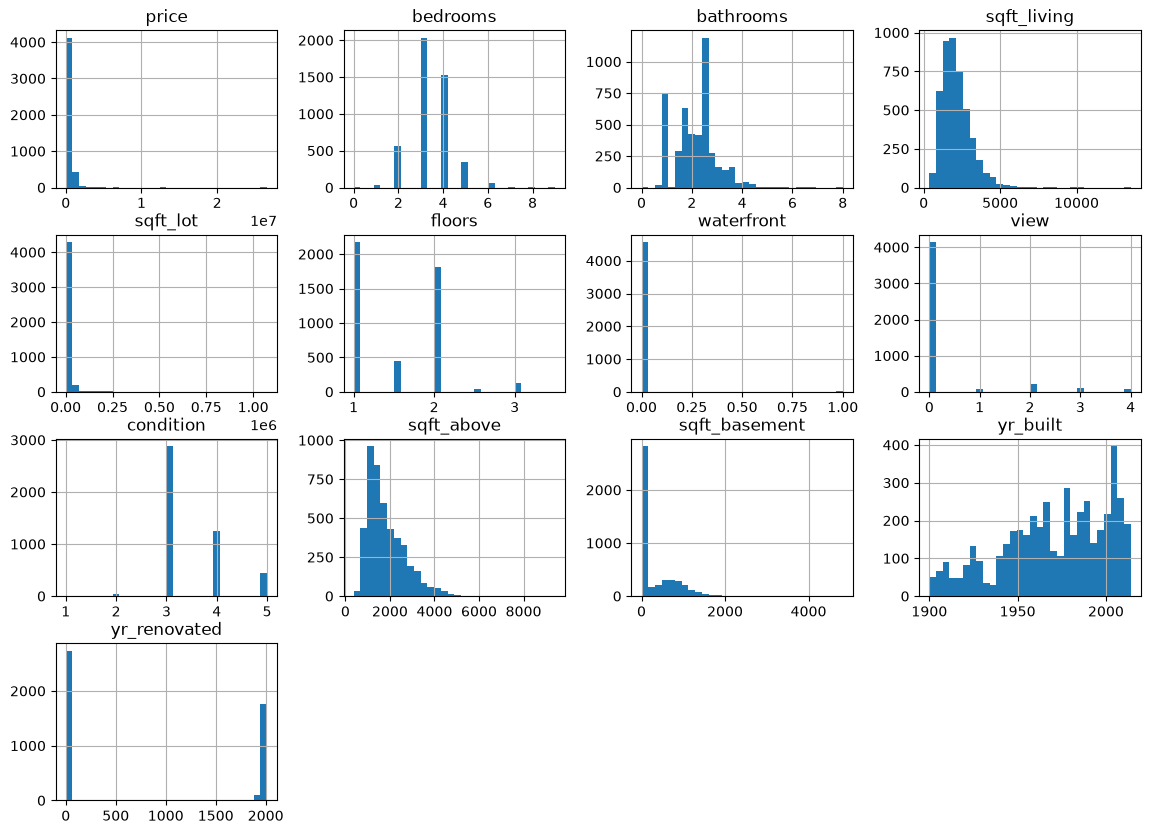

In [442]:
data.hist(bins=30, figsize=(14, 10))

### 3.5 Observations from Histograms

The histograms cover the 13 numeric columns of the raw data (4,600 records, before cleaning).

| Column | Shape of the distribution | Observation | Planned action |
|---|---|---|---|
| `price` | Heavily right-skewed | About 92% of houses cost less than 1,000,000, but the axis extends to 26,590,000. A few extreme values stretch the chart. | Remove zero prices. Check extreme values for invalid records (Section 4). |
| `bedrooms` | Peak at 3, concentrated between 3 and 4 | About 78% of houses have 3 or 4 bedrooms. Two records have 0 and the maximum is 9. | Inspect and remove records with 0 bedrooms. |
| `bathrooms` | Peak at 2.5, values in steps of 0.25 | About 90% of houses have between 1 and 3 bathrooms. Two records have 0 and the maximum is 8. | Inspect and remove records with 0 bathrooms. |
| `sqft_living` | Right-skewed | About 96% of houses are below 4,000 sq ft. A small number of very large houses form a long tail up to 13,540. | Keep as the main size feature. Check large values against their prices. |
| `sqft_lot` | Very strongly right-skewed | About 88% of lots are below 20,000 sq ft, but the maximum is 1,074,218. Almost all bars are on the far left. | Check its relationship with price before using it. |
| `floors` | Discrete values: 1, 1.5, 2, 2.5, 3, 3.5 | Mostly 1 floor (47%) or 2 floors (39%). Values of 2.5 and above are rare. | Use as a small-valued numeric feature. |
| `waterfront` | Two bars: 0 and 1 | Only about 0.7% of houses are on the waterfront. | Keep as a binary feature. Rarity means a low correlation does not make it unimportant. |
| `view` | Rating 0 to 4 with one dominant bar | About 90% of houses have a view rating of 0. | Treat as an ordinal rating. |
| `condition` | Rating 1 to 5, peak at 3 | About 63% of houses have a condition of 3. Ratings of 1 and 2 are very rare. | Treat as an ordinal rating. |
| `sqft_above` | Right-skewed, similar to `sqft_living` | The shape closely follows `sqft_living`. | Test whether it duplicates `sqft_living` (Section 5). |
| `sqft_basement` | One tall bar at 0, a small spread above | About 60% of houses have no basement. | Test whether `sqft_above + sqft_basement = sqft_living` (Section 5). |
| `yr_built` | Fairly even, with fewer houses before 1940 | Values range from 1900 to 2014. Each 20-year period from 1940 onward contains roughly 900 to 1,000 houses. No impossible values. | Check its relationship with price. |
| `yr_renovated` | One tall bar at 0, a small spread near 2000 | About 60% of records have the value 0, which is not a real year. | Determine what 0 represents and encode it appropriately (Section 5). |

The histograms describe the data only. Decisions about removing or transforming columns are made in Sections 4 and 5, after the analysis.

## 4. Data Cleaning

### 4.1 Zero Prices
A sale cannot have a price of zero, so these records are treated as invalid data and removed.

In [443]:
print("Records with price=0 :", (data["price"] == 0).sum())

Records with price=0 : 49


In [444]:
print("Records before cleaning:", len(data))
mask = data["price"] != 0
data = data[mask]
data = data.reset_index(drop=True)
print("Records after cleaning:", len(data))

Records before cleaning: 4600
Records after cleaning: 4551


### 4.2 Zero Bedrooms and Bathrooms
Records with zero bedrooms or zero bathrooms are inspected before removal.

In [445]:
data[(data["bedrooms"] == 0) | (data["bathrooms"] == 0)][["price", "bedrooms", "bathrooms", "sqft_living", "city"]]

,price,bedrooms,bathrooms,sqft_living,city
2365,1095000.0,0.0,0.0,3064,Seattle
3209,1295648.0,0.0,0.0,4810,Redmond


In [446]:
print("Records before cleaning:", len(data))
mask = (data["bedrooms"] != 0) & (data["bathrooms"] != 0)
data = data[mask]
data = data.reset_index(drop=True)
print("Records after cleaning:", len(data))

Records before cleaning: 4551
Records after cleaning: 4549


### 4.3 Price Outliers
A temporary column, price per square foot, is created to compare houses of different sizes. Unusually high or low values indicate invalid records.

In [447]:
data["price_per_sqft"] = data["price"] / data["sqft_living"]
data["price_per_sqft"].describe().round(1)

count     4549.0
mean       268.7
std        358.4
min         10.0
25%        182.9
50%        245.4
75%        315.7
max      22533.9
Name: price_per_sqft, dtype: float64

The houses with the lowest and highest price per square foot are inspected to choose a valid range.

In [448]:
data.sort_values("price_per_sqft").head(8)[["price", "sqft_living", "price_per_sqft", "city"]]

,price,sqft_living,price_per_sqft,city
4349,7800.0,780,10.000000,Tukwila
4343,84350.0,2630,32.072243,Yarrow Point
4382,195000.0,5340,36.516854,Seattle
4390,83300.0,1490,55.906040,Covington
4347,188000.0,3260,57.668712,Medina
4436,132250.0,2192,60.333029,Kent
4394,83300.0,1370,60.802920,Covington
4373,107500.0,1590,67.610063,Enumclaw


In [449]:
data.sort_values("price_per_sqft").tail(8)[["price", "sqft_living", "price_per_sqft", "city"]]

,price,sqft_living,price_per_sqft,city
3776,2.760000e+05,370,745.945946,Seattle
478,1.200000e+06,1560,769.230769,Mercer Island
404,2.400000e+06,3000,800.000000,Sammamish
4345,2.110000e+06,2100,1004.761905,Tukwila
4439,2.560498e+06,1710,1497.367446,Seattle
4346,2.199900e+06,1120,1964.196429,Covington
4344,1.289900e+07,2190,5889.954338,Seattle
4348,2.659000e+07,1180,22533.898305,Kent


**Method:** Price per square foot (`price / sqft_living`) was calculated for every record, so that houses of different sizes could be compared on the same scale.

**Observation:**
- The median price per square foot is about 245, and the middle 50% of records fall between 183 and 316.
- The minimum is 10 and the maximum is 22,534. Both are far outside this range.
- The extreme records show prices that are inconsistent with the house size. Examples: 26,590,000 for 1,180 sq ft, 12,899,000 for 2,190 sq ft, and 7,800 for 780 sq ft.

**Decision:** Records with a price per square foot below 50 or above 1,000 are removed.
- The range is deliberately wide. The lower limit is about one fifth of the median and the upper limit is about four times the median, so only extreme values are affected.
- Linear regression minimizes squared error, so a few extreme values can pull the fitted line away from the typical houses.
- Only 8 of 4,549 records (about 0.2%) are removed, so almost no data is lost.

**Limitation:** The thresholds are chosen by inspecting the data and are a judgement, not a fixed rule. A different cut-off would remove a slightly different set of records.

In [450]:
print("Records before cleaning:", len(data))
mask = (data["price_per_sqft"] >= 50) & (data["price_per_sqft"] <= 1000)
data = data[mask]
data = data.reset_index(drop=True)
print("Records after cleaning:", len(data))

Records before cleaning: 4549
Records after cleaning: 4541


The `price_per_sqft` column was created only for cleaning. It is calculated from the target (`price`), so it must not be used as a feature. It is removed.

In [451]:
data = data.drop(columns=["price_per_sqft"])
data.shape

(4541, 18)

## 5. Feature Analysis

### 5.1 Distinct Values per Column
The number of distinct values in each column shows what kind of variable it is (flag, rating, measurement or text) and whether it can be used as a model input.

In [452]:
data.nunique().sort_values()

country             1
waterfront          2
condition           5
view                5
floors              6
bedrooms            9
bathrooms          25
city               44
yr_renovated       59
date               70
statezip           77
yr_built          115
sqft_basement     207
sqft_above        508
sqft_living       558
price            1733
sqft_lot         3078
street           4466
dtype: int64

### 5.2 Initial Column Assessment

Columns are grouped by the number of distinct values and the type of data.

| Decision | Columns | Reason |
|:---|:---|:---|
| Excluded | `country` | Single value for all records; no predictive information |
| Excluded | `street` | Nearly unique for every record; cannot generalise to new houses |
| Target | `price` | Variable to be predicted |
| Candidate features | `waterfront`, `condition`, `view`, `floors`, `bedrooms`, `bathrooms`, `yr_built`, `sqft_basement`, `sqft_above`, `sqft_living`, `sqft_lot` | Numeric values with a direct relation to the house |
| Requires further analysis | `city`, `statezip`, `date`, `yr_renovated` | Text, date or special-coded values; to be examined before a decision |

In [453]:
print("Columns before:", data.shape[1])
data = data.drop(columns=["country", "street"])
print("Columns after:", data.shape[1])

Columns before: 18
Columns after: 16


### 5.3 Correlation with Price

The correlation of each candidate feature with `price` is calculated.

Correlation is a number from -1 to +1 that shows how strongly two columns move together:
- Close to +1: when the column goes up, the price goes up.
- Close to 0: no clear relationship.
- Close to -1: when the column goes up, the price goes down.

In [454]:
candidates = ["waterfront", "condition", "view", "floors", "bedrooms", "bathrooms",
              "yr_built", "sqft_basement", "sqft_above", "sqft_living", "sqft_lot"]

corr_with_price = data[candidates].corrwith(data["price"])
corr_with_price.sort_values(ascending=False).round(3)

sqft_living      0.706
sqft_above       0.605
bathrooms        0.532
view             0.384
sqft_basement    0.342
bedrooms         0.338
floors           0.258
waterfront       0.234
sqft_lot         0.084
condition        0.051
yr_built         0.024
dtype: float64

<Axes: title={'center': 'Correlation of each feature with price'}>

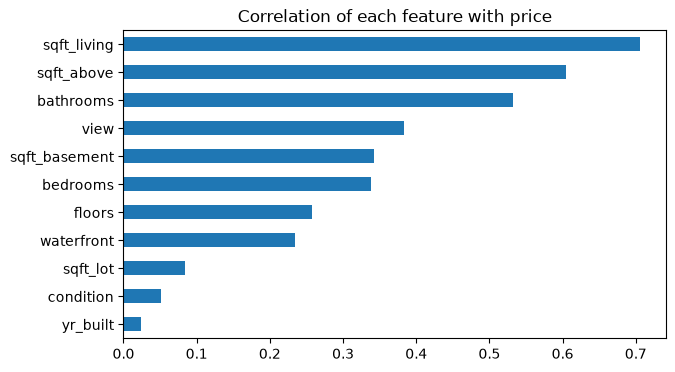

In [455]:
corr_with_price.sort_values().plot.barh(title="Correlation of each feature with price", figsize=(7, 4))

### 5.4 Observations from Correlation

| Strength | Columns | Correlation with price |
|---|---|---|
| Strong | `sqft_living`, `sqft_above`, `bathrooms` | 0.53 to 0.71 |
| Moderate | `view`, `sqft_basement`, `bedrooms` | 0.34 to 0.38 |
| Weak | `floors`, `waterfront` | 0.23 to 0.26 |
| Very weak | `sqft_lot`, `condition`, `yr_built` | below 0.10 |

Correlation measures only linear relationships, so a low value does not by itself justify excluding a column. The three area columns (`sqft_living`, `sqft_above`, `sqft_basement`) may be related to each other and are checked for redundancy next.

In [456]:
check = data["sqft_above"] + data["sqft_basement"]
print("Records where above + basement equals living:", (check == data["sqft_living"]).sum())
print("Total records:", len(data))

Records where above + basement equals living: 4541
Total records: 4541


### 5.5 Redundant Area Columns

For all 4,541 records, `sqft_above + sqft_basement = sqft_living`. The total area column therefore already contains the information of the other two.

**Decision:** `sqft_living` is retained. `sqft_above` and `sqft_basement` are excluded.

**Reason:** Using all three would introduce perfect multicollinearity, because one feature is an exact linear combination of the others. This makes the regression coefficients non-unique and unstable. `sqft_living` also has the highest correlation with price (0.71) of the three.

In [457]:
print("Columns before:", data.shape[1])
data = data.drop(columns=["sqft_above", "sqft_basement"])
print("Columns after:", data.shape[1])

Columns before: 16
Columns after: 14


### 5.6 Renovation Year

`yr_renovated` contains the value `0` for many records: the minimum, the 25th percentile and the median in the summary statistics were all 0. Since 0 is not a valid year, its meaning must be understood before the column is used. The most common values are checked below.

In [458]:
data["yr_renovated"].value_counts().head(5)

yr_renovated
0       2703
2000     169
2003     150
2009     105
2001     105
Name: count, dtype: int64

`yr_renovated` contains the value 0 for about 60% of records. All other values are valid years (for example 2000, 2003, 2009), so 0 represents a house that was never renovated.

Used directly, the column would mix a "no renovation" code with calendar years, and a linear model would treat the difference between 0 and 2000 as a numerical distance.  
The column is therefore converted to a binary feature `renovated` (0 = never renovated, 1 = renovated).

In [459]:
data["renovated"] = (data["yr_renovated"] > 0).astype(int)
data["renovated"].value_counts()

renovated
0    2703
1    1838
Name: count, dtype: int64

### 5.7 Renovated vs Non-Renovated Houses
Renovated houses have a lower median price than non-renovated houses. This is unexpected, so the two groups are compared on size and year built to check whether other differences explain it.

In [460]:
data.groupby("renovated")[["price", "sqft_living", "yr_built"]].median()

,price,sqft_living,yr_built
renovated,,,
0,482000.0,2060.0,1986.0
1,449500.0,1830.0,1958.0


Renovated houses have a lower median price (449,500) than non-renovated houses (482,000). They are also smaller (1,830 vs 2,060 sq ft median) and older (median year built 1958 vs 1986), which explains the price difference.

**Decision:**
- `renovated` (binary) is retained as a candidate feature. In a multiple regression, its effect is estimated while `sqft_living` and `yr_built` are held constant.
- `yr_renovated` is excluded, because it mixes the code 0 (never renovated) with calendar years.

In [461]:
print("Columns before:", data.shape[1])
data = data.drop(columns=["yr_renovated"])
print("Columns after:", data.shape[1])

Columns before: 15
Columns after: 14


### 5.8 Weak Features

Several candidate features appear to have a very weak linear correlation with price. Their correlations are calculated first, including the new `renovated` column, which was not part of the correlation table in 5.3.

In [512]:
weak = ["renovated", "condition", "yr_built", "sqft_lot"]
data[weak].corrwith(data["price"]).round(3)

renovated   -0.043
condition    0.051
yr_built     0.024
sqft_lot     0.084
dtype: float64

All four correlations are close to zero. Pairwise correlation ignores the effect of the other features and measures only straight-line relationships, so it is not used alone to exclude a column.

**Decision:** These features are retained. Their effect is estimated together with the other features in the model.

### 5.9 Sale Date

`date` is the date of sale. Its range is checked to decide whether it can explain differences in price.

In [462]:
data["date"] = pd.to_datetime(data["date"])
print("Earliest sale:", data["date"].min())
print("Latest sale  :", data["date"].max())

Earliest sale: 2014-05-02 00:00:00
Latest sale  : 2014-07-10 00:00:00


All sales occurred between 2014-05-02 and 2014-07-10, a period of about 10 weeks. Market conditions are essentially constant over this span, so `date` cannot explain price differences between houses.

**Decision:** `date` is excluded.

In [463]:
print("Columns before:", data.shape[1])
data = data.drop(columns=["date"])
print("Columns after:", data.shape[1])

Columns before: 14
Columns after: 13


### 5.10 Location: City

`city` has 44 distinct values.  
The number of houses and the median price per city are examined to decide whether location explains price differences.

In [464]:
city_summary = data.groupby("city")["price"].agg(["count", "median"])
city_summary = city_summary.sort_values("count", ascending=False)
city_summary.head(10)

,count,median
city,,
Seattle,1557,490000.0
Renton,291,345000.0
Bellevue,281,725000.0
Redmond,234,636500.0
Kirkland,187,522000.0
Issaquah,186,561000.0
Kent,183,283200.0
Auburn,175,276000.0
Sammamish,171,668500.0


Median prices differ strongly between cities with a large number of records, for example Bellevue (725,000) and Auburn (276,000). Location therefore explains price differences that area and room counts do not.

**Problem:** `city` is text, and a regression model can only use numbers. It must be converted before use.

In [465]:
cutoff = 50
big_cities = city_summary[city_summary["count"] >= cutoff]

print("Cities with at least", cutoff, "houses:", len(big_cities))
print("Houses in those cities:", big_cities["count"].sum(), "out of", len(data))

Cities with at least 50 houses: 19
Houses in those cities: 4138 out of 4541


A separate 0/1 column for each of the 44 cities would create many columns based on very few records.

**Decision:** Cities with at least 50 records (19 cities, covering 4,138 of 4,541 records) keep their own category. All remaining cities are grouped into a single category, `Other`.

In [466]:
data["city_group"] = data["city"].where(data["city"].isin(big_cities.index), "Other")
data["city_group"].value_counts()

city_group
Seattle          1557
Other             403
Renton            291
Bellevue          281
Redmond           234
Kirkland          187
Issaquah          186
Kent              183
Auburn            175
Sammamish         171
Federal Way       145
Shoreline         123
Woodinville       114
Maple Valley       95
Mercer Island      82
Burien             72
Snoqualmie         69
Kenmore            65
Des Moines         58
North Bend         50
Name: count, dtype: int64

### 5.11 Location: Zip Code

`statezip` has 77 distinct values, compared with 44 for `city`. The number of zip codes within each city is checked to see whether it is a finer version of the same information.

In [467]:
data.groupby("city")["statezip"].nunique().sort_values(ascending=False).head(5)

city
Seattle     25
Bellevue     5
Renton       5
Burien       4
Kent         4
Name: statezip, dtype: int64

`statezip` is a finer subdivision of `city`: each zip code belongs to a single city, and Seattle alone contains 25 zip codes. It therefore carries additional neighbourhood-level information.

**Decision:** `statezip` is not used in the first model, because encoding every zip code as a separate binary column would add about 46 columns. `city_group` is used as the location feature. A more compact way of using zip code is tested in Section 12.

**Limitation:** Price variation between neighbourhoods within a large city (especially Seattle, 1,557 records) is not captured by this model.

### 5.12 One-Hot Encoding of City

`city_group` is converted into one binary column per category (20 columns). The `Other` column is then dropped, for these reasons:
- With all 20 columns present, every row sums to 1, so any column can be derived from the others (the *dummy variable trap*). This makes the regression coefficients non-unique.
- After `Other` is dropped, a house with zeros in all remaining city columns belongs to `Other`.
- Each city's weight is therefore interpreted relative to `Other`.

In [468]:
city_dummies = pd.get_dummies(data["city_group"], prefix="city", dtype=int)
city_dummies = city_dummies.drop(columns=["city_Other"])
print("Number of city columns:", city_dummies.shape[1])
city_dummies.head()

Number of city columns: 19


,city_Auburn,city_Bellevue,city_Burien,city_Des Moines,city_Federal Way,city_Issaquah,city_Kenmore,city_Kent,city_Kirkland,city_Maple Valley,city_Mercer Island,city_North Bend,city_Redmond,city_Renton,city_Sammamish,city_Seattle,city_Shoreline,city_Snoqualmie,city_Woodinville
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
2,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
3,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0


## 6. Final Dataset

**Features (29 columns):**
- 10 numeric features: `sqft_living`, `bathrooms`, `bedrooms`, `floors`, `waterfront`, `view`, `condition`, `sqft_lot`, `yr_built`, `renovated`
- 19 binary city columns from the one-hot encoding (the `Other` group is the reference category)

**Target:** `price`

Columns excluded during analysis: `country`, `street`, `sqft_above`, `sqft_basement`, `yr_renovated`, `date`, `statezip`, `city`, `city_group`.

In [469]:
feature_cols = ["sqft_living", "bathrooms", "bedrooms", "floors", "waterfront",
                "view", "condition", "sqft_lot", "yr_built", "renovated"]

features = pd.concat([data[feature_cols], city_dummies], axis=1)
target = data["price"]

print("Features shape:", features.shape)
print("Target shape  :", target.shape)
print("Missing values:", features.isna().sum().sum())

Features shape: (4541, 29)
Target shape  : (4541,)
Missing values: 0


## 7. NumPy Arrays

### 7.1 Conversion
The feature table and target are converted to NumPy arrays. `X` is a 2-D array (rows are houses, columns are features) and `y` is a 1-D array of prices.

In [470]:
X = features.to_numpy(dtype=float)
y = target.to_numpy(dtype=float)

In [471]:
print("X (first 3 houses):")
print(X[:3].round(2))
print("\ny (first 5 prices):", y[:5])

X (first 3 houses):
[[ 1340.      1.5     3.      1.5     0.      0.      3.   7912.   1955.
      1.      0.      0.      0.      0.      0.      0.      0.      0.
      0.      0.      0.      0.      0.      0.      0.      0.      1.
      0.      0. ]
 [ 3650.      2.5     5.      2.      0.      4.      5.   9050.   1921.
      0.      0.      0.      0.      0.      0.      0.      0.      0.
      0.      0.      0.      0.      0.      0.      0.      1.      0.
      0.      0. ]
 [ 1930.      2.      3.      1.      0.      0.      4.  11947.   1966.
      0.      0.      0.      0.      0.      0.      0.      0.      1.
      0.      0.      0.      0.      0.      0.      0.      0.      0.
      0.      0. ]]

y (first 5 prices): [ 313000. 2384000.  342000.  420000.  550000.]


### 7.2 Array Inspection
`size` is the total number of elements and `shape` is the dimensions. `X` has two dimensions (houses × features), while `y` has one.

In [472]:
print("X -> size:", X.size, "| shape:", X.shape, "| dimensions:", X.ndim)
print("y -> size:", y.size, "| shape:", y.shape, "| dimensions:", y.ndim)
print("Number of houses  :", X.shape[0])
print("Number of features:", X.shape[1])

X -> size: 131689 | shape: (4541, 29) | dimensions: 2
y -> size: 4541 | shape: (4541,) | dimensions: 1
Number of houses  : 4541
Number of features: 29


### 7.3 Indexing
Indexing starts at 0, so the third house is at index 2. `X[2]` returns the full row of features for that house, and `y[2]` returns its price.

In [473]:
np.set_printoptions(suppress=True)     # print normal numbers instead of scientific notation
print("Third house features:", X[2].round(2))
print("Third house price   : $", f"{y[2]:,.0f}")

Third house features: [ 1930.     2.     3.     1.     0.     0.     4. 11947.  1966.     0.
     0.     0.     0.     0.     0.     0.     0.     1.     0.     0.
     0.     0.     0.     0.     0.     0.     0.     0.     0.]
Third house price   : $ 342,000


### 7.4 Adding a Record
A new house is created by copying an existing row and changing its values. `np.vstack` appends the row to `X`, and `np.append` appends the price to `y`. Both return new arrays, so the originals are kept unchanged for modelling.

In [474]:
new_house = X[2].copy()
new_house[0] = 1800          # sqft_living
new_house[1] = 2             # bathrooms
new_house[2] = 3             # bedrooms
new_price = 450000

X_extended = np.vstack([X, new_house])
y_extended = np.append(y, new_price)

print("Houses before:", X.shape[0])
print("Houses after :", X_extended.shape[0])
print("Last house   :", X_extended[-1][:3], "| price:", y_extended[-1])

Houses before: 4541
Houses after : 4542
Last house   : [1800.    2.    3.] | price: 450000.0


### 7.5 Statistics with NumPy
The mean, minimum, maximum, median and standard deviation are calculated with NumPy for the cleaned data. `X[:, 0]` is the first column of `X` (`sqft_living`) for all houses.

In [475]:
sizes = X[:, 0]
prices = y

stats = pd.DataFrame({
    "sqft_living": [np.mean(sizes), np.min(sizes), np.max(sizes), np.median(sizes), np.std(sizes)],
    "price ($)":   [np.mean(prices), np.min(prices), np.max(prices), np.median(prices), np.std(prices)],
}, index=["mean", "min", "max", "median", "std"])


stats.round(1)

,sqft_living,price ($)
mean,2131.6,548335.7
min,370.0,80000.0
max,13540.0,7062500.0
median,1970.0,465000.0
std,954.3,365303.6


#### Observations from the NumPy Statistics
- **Price:** The mean (548,336) is higher than the median (465,000), so more than half of the houses cost less than the average. A small number of very expensive houses pull the mean upwards.
- **Spread of price:** The standard deviation (365,304) is about 67% of the mean, so prices vary widely between houses.
- **Size:** Sizes range from 370 to 13,540 sq ft. The median is 1,970 sq ft, so the largest house is about 7 times the typical size, and a few large houses stretch the range.
- **Effect of an unusual house:** One extremely expensive house would raise the mean, because the mean uses every value. The median would barely change, because it depends only on the middle value. This is tested in Challenge A.

### 7.6 Relationship Between Size and Price
The price difference and size difference of two houses are compared to see how much extra price each extra square foot brings.

In [476]:
i, j = 0, 2     # try other houses too

price_diff = y[j] - y[i]
size_diff = X[j, 0] - X[i, 0]

print(f"House {i}: {X[i, 0]:.0f} sq ft, ${y[i]:,.0f}")
print(f"House {j}: {X[j, 0]:.0f} sq ft, ${y[j]:,.0f}")
print(f"Price difference: ${price_diff:,.0f}")
print(f"Size difference : {size_diff:.0f} sq ft")
print(f"Extra price per extra sq ft: ${price_diff / size_diff:,.1f}")

House 0: 1340 sq ft, $313,000
House 2: 1930 sq ft, $342,000
Price difference: $29,000
Size difference : 590 sq ft
Extra price per extra sq ft: $49.2


In [477]:
rng = np.random.default_rng(1)

for _ in range(5):
    first, second = rng.choice(len(X), size=2, replace=False)
    rate = (y[second] - y[first]) / (X[second, 0] - X[first, 0])
    print(f"Sizes {X[first, 0]:.0f} and {X[second, 0]:.0f} sq ft -> extra ${rate:,.1f} per extra sq ft")

Sizes 2610 and 2180 sq ft -> extra $462.1 per extra sq ft
Sizes 720 and 1170 sq ft -> extra $51.4 per extra sq ft
Sizes 1770 and 1640 sq ft -> extra $-4,447.2 per extra sq ft
Sizes 2740 and 1296 sq ft -> extra $79.7 per extra sq ft
Sizes 1050 and 2600 sq ft -> extra $188.5 per extra sq ft


#### Observations on Size and Price

- The extra price per extra square foot is not the same for every pair of houses. Four of the five sample pairs gave positive rates between about $51 and $462 per square foot.
- One pair gave a negative rate (about −$4,447 per square foot), because the larger house was the cheaper one. This happens when factors other than size, such as location, view or condition, outweigh the size difference.
- Size alone therefore does not determine price. This is why the model uses additional features such as bathrooms, view, waterfront and location.

### 7.7 Scatter Plot and Correlation
Each point is one house. The correlation coefficient measures how closely the points follow a straight line (1 = perfect upward line, 0 = no linear relationship).

Correlation: 0.706


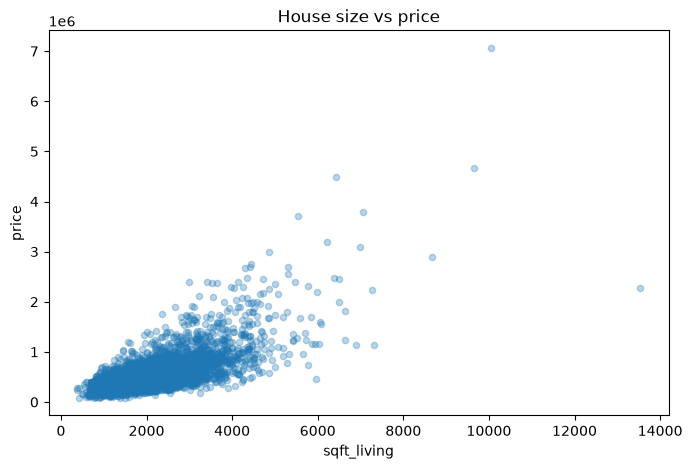

In [478]:
data.plot.scatter(x="sqft_living", y="price", alpha=0.3, figsize=(8, 5), title="House size vs price")

print("Correlation:", np.corrcoef(X[:, 0], y)[0, 1].round(3))

In [479]:
rough_rate = np.median(y / X[:, 0])

print(f"Typical price per square foot: ${rough_rate:,.1f}")
print(f"Rough prediction for 1,500 sq ft: ${rough_rate * 1500:,.0f}")

Typical price per square foot: $245.4
Rough prediction for 1,500 sq ft: $368,098


In [511]:
similar = data[(data["sqft_living"] >= 1400) & (data["sqft_living"] <= 1600)]["price"]

print("Houses between 1,400 and 1,600 sq ft:", len(similar))
print(f"Median price : ${similar.median():,.0f}")
print(f"Minimum price: ${similar.min():,.0f}")
print(f"Maximum price: ${similar.max():,.0f}")
print(f"Rough prediction for 1,500 sq ft: ${rough_rate * 1500:,.0f}")

Houses between 1,400 and 1,600 sq ft: 471
Median price : $395,000
Minimum price: $83,300
Maximum price: $1,200,000
Rough prediction for 1,500 sq ft: $368,098


#### Rough Prediction

The typical price per square foot is about $245, so a 1,500 sq ft house is predicted at about $368,098.

The check above compares this prediction with the actual prices of houses between 1,400 and 1,600 sq ft. Their median shows whether the rule is reasonable for a typical house, and the gap between their minimum and maximum shows how much price varies at the same size.

This rule uses size alone, so it cannot account for location, condition or other features. This is why the model in Section 9 uses all of them.

## 8. Train/Test Split

The data is shuffled and then split 80% for training and 20% for testing. The same shuffled order is applied to `X` and `y`, so each house stays paired with its own price. `X` and `y` themselves are not changed, so the cells can be re-run safely.

In [480]:
np.random.seed(42)                         # fixed seed: same shuffle every run
order = np.random.permutation(len(X))      # shuffled row positions

X_shuffled = X[order]
y_shuffled = y[order]

In [481]:
split = int(0.8 * len(X))

X_train = X_shuffled[:split]
y_train = y_shuffled[:split]
X_test = X_shuffled[split:]
y_test = y_shuffled[split:]

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)

X_train: (3632, 29) | y_train: (3632,)
X_test : (909, 29) | y_test : (909,)


The first five sizes and prices of each set are printed to inspect them, because the full arrays are too large to print. `X_train[:5, 0]` selects `sqft_living` (column 0) for the first five training houses.

In [ ]:
print("X_train sizes (first 5):", X_train[:5, 0])
print("y_train prices (first 5):", y_train[:5])
print("X_test sizes (first 5)  :", X_test[:5, 0])
print("y_test prices (first 5) :", y_test[:5])
print("Training examples:", len(X_train), "| Test examples:", len(X_test))

X_train sizes (first 5): [2180. 1490. 1980. 1370. 2230.]
y_train prices (first 5): [325000. 745000. 307550. 300000. 253000.]
X_test sizes (first 5)  : [1850. 1210. 2000. 1330. 2360.]
y_test prices (first 5) : [489200. 324950. 420000. 900000. 590000.]
Training examples: 3632 | Test examples: 909


### 8.1 Pairing Check
The first training house is compared with its row in the original data to confirm that its size and price still belong together.

In [483]:
i = order[0]     # original row position of the first training house

print("Original data -> size:", data.loc[i, "sqft_living"], "| price:", data.loc[i, "price"])
print("Training data -> size:", X_train[0, 0], "| price:", y_train[0])

Original data -> size: 2180 | price: 325000.0
Training data -> size: 2180.0 | price: 325000.0


### 8.2 Why Test on Unseen Data

The model is fitted using the training data, so it has already seen those houses and their prices.  
Its error on the training data would therefore look better than its true performance. Evaluating on the test set, which was not used for fitting, shows how well the model predicts new houses.

## 9. Model: Multiple Linear Regression

With several features, the price is predicted as a weighted sum:

`price = w1·x1 + w2·x2 + ... + w29·x29 + b`

where `x1 ... x29` are the 29 features of a house, `w1 ... w29` are their weights (how many dollars each feature adds to the price) and `b` is the intercept.

The weights are estimated from the training data by **least squares**: the values are chosen so that the total squared difference between actual and predicted training prices is as small as possible.

### 9.0 Adding an Intercept Column

A column of ones is added at the front of `X_train`, so that the intercept `b` is learned like any other weight (it is multiplied by 1 for every house). The result, `X_train_b`, has 30 columns: one for the intercept and 29 for the features.

In [484]:
ones = np.ones(len(X_train))
X_train_b = np.column_stack([ones, X_train])

print("X_train shape  :", X_train.shape)
print("X_train_b shape:", X_train_b.shape)

X_train shape  : (3632, 29)
X_train_b shape: (3632, 30)


### 9.1 Fitting the Model

The weights are estimated with `np.linalg.lstsq`, which finds the values that minimise the sum of squared errors on the training data. The first value returned is the intercept `b`, and the remaining 29 are the feature weights.

In [485]:
weights, residuals, rank, sv = np.linalg.lstsq(X_train_b, y_train, rcond=None)

b = weights[0]
w = weights[1:]

print("Number of weights:", len(w))
print("Intercept b:", round(b, 2))

Number of weights: 29
Intercept b: 2643072.6


### 9.2 Learned Weights

Each weight shows how much the predicted price changes when that feature increases by one unit, with all other features held constant. For binary city columns, the weight is the price difference relative to the reference group `Other`.

In [486]:
weights_table = pd.Series(w, index=features.columns)
weights_table.round(1)

sqft_living              252.1
bathrooms              36297.9
bedrooms              -42616.0
floors                 48027.5
waterfront            333744.0
view                   49581.6
condition              27895.0
sqft_lot                  -0.4
yr_built               -1416.5
renovated               9990.8
city_Auburn          -135596.3
city_Bellevue         215674.9
city_Burien          -100510.0
city_Des Moines      -133740.9
city_Federal Way     -170737.2
city_Issaquah          52240.3
city_Kenmore          -30084.7
city_Kent            -134902.1
city_Kirkland         137387.4
city_Maple Valley    -111570.5
city_Mercer Island    338788.6
city_North Bend       -45595.8
city_Redmond          104761.0
city_Renton           -92895.6
city_Sammamish         39982.0
city_Seattle          114863.0
city_Shoreline          2456.0
city_Snoqualmie       -61207.8
city_Woodinville       20835.5
dtype: float64

### 9.3 Interpretation of Weights

Each weight is the change in predicted price for a one-unit increase in that feature, holding all other features constant. Weights are estimated from observational data and describe associations, not causes.

**Size and rooms**

| Feature | Weight | Interpretation |
|---|---|---|
| `sqft_living` | +252 | Each additional square foot adds about 252. |
| `bathrooms` | +36,298 | Each additional bathroom adds about 36,000. |
| `bedrooms` | -42,616 | Negative because `sqft_living` is held constant: more bedrooms in the same area means smaller rooms. |
| `floors` | +48,028 | Each additional floor adds about 48,000. |
| `sqft_lot` | -0.4 | Effectively zero. A lot 10,000 sq ft larger changes the prediction by about -4,000. |

**Quality and condition**

| Feature | Weight | Interpretation |
|---|---|---|
| `waterfront` | +333,744 | Waterfront houses are predicted to cost about 334,000 more. |
| `view` | +49,582 | Each step up the 0-4 view rating adds about 50,000. |
| `condition` | +27,895 | Each step up the 1-5 condition rating adds about 28,000. |
| `renovated` | +9,991 | Renovated houses are predicted to cost about 10,000 more. This is a small effect. |
| `yr_built` | -1,416 | Each later year of construction lowers the prediction by about 1,400. Older houses are predicted to cost more, which is unexpected. Possible reasons are that older houses are in established areas and that city only partly captures location. |

**City** (difference relative to the reference group `Other`)

| Higher than `Other` | Weight | Lower than `Other` | Weight |
|---|---|---|---|
| Mercer Island | +338,789 | Federal Way | -170,737 |
| Bellevue | +215,675 | Auburn | -135,596 |
| Kirkland | +137,387 | Kent | -134,902 |
| Seattle | +114,863 | Des Moines | -133,741 |
| Redmond | +104,761 | Maple Valley | -111,571 |
| Issaquah | +52,240 | Burien | -100,510 |
| Sammamish | +39,982 | Renton | -92,896 |
| Woodinville | +20,836 | Snoqualmie | -61,208 |
| Shoreline | +2,456 | North Bend | -45,596 |
|  |  | Kenmore | -30,085 |

**Note:** Weights of different features cannot be compared directly, because the units differ (square feet, years, yes/no flags).

### 9.4 Prediction Function
The model predicts a price as the intercept plus the sum of each feature multiplied by its weight. `np.dot` does this multiplication and sum in one step. It is checked on the first test house.

In [487]:
def predict_price(features_row):
    return b + np.dot(features_row, w)

print("Predicted price of first test house:", round(predict_price(X_test[0])))
print("Actual price of first test house   :", y_test[0])

Predicted price of first test house: 642923
Actual price of first test house   : 489200.0


## 10. Model Evaluation

### 10.1 Test Predictions
Prices are predicted for all test houses, which were not used for fitting. The prediction error is defined as actual price minus predicted price.

In [488]:
y_pred = predict_price(X_test)
errors = y_test - y_pred

print("Predictions shape:", y_pred.shape)
print("First 5 actual   :", y_test[:5])
print("First 5 predicted:", y_pred[:5].round(0))
print("First 5 errors   :", errors[:5].round(0))

Predictions shape: (909,)
First 5 actual   : [489200. 324950. 420000. 900000. 590000.]
First 5 predicted: [642923. 236882. 692479. 401560. 497601.]
First 5 errors   : [-153723.   88068. -272479.  498440.   92399.]


### 10.2 Mean Absolute Error (MAE)

MAE is the average of the absolute prediction errors. It is expressed in the unit of the target (US dollars), so it can be read directly as the typical size of a prediction error.

`MAE = mean(|actual - predicted|)`

In [489]:
mae = np.mean(np.abs(errors))
print("MAE: $", f"{mae:,.0f}")

MAE: $ 126,934


### 10.3 Mean Squared Error (MSE)

MSE is the average of the squared prediction errors. Squaring gives large errors more weight than small ones. It is expressed in squared dollars, so it is harder to interpret directly. The square root (RMSE) returns it to dollars.

`MSE = mean((actual - predicted)²)`

In [490]:
mse = np.mean(errors ** 2)
rmse = np.sqrt(mse)

print("MSE :", f"{mse:,.0f}")
print("RMSE: $", f"{rmse:,.0f}")

MSE : 50,844,207,968
RMSE: $ 225,487


### 10.4 Metric Comparison

MAE is easier to interpret because it is in the same unit as the target (US dollars) and states directly the average size of a prediction error: the model is typically off by about $127,000.

MSE is in squared dollars, so its value (about 50.8 billion) cannot be read as a price. RMSE ($225,487) converts it back to dollars. MSE is useful for penalising large errors, because squaring gives them more weight.

## 11. Baseline Comparison

A baseline model predicts the average training price for every house. If the regression model has learned useful patterns, its test error should be clearly lower than the baseline's.

In [491]:
baseline_pred = np.mean(y_train)
baseline_errors = y_test - baseline_pred
baseline_mae = np.mean(np.abs(baseline_errors))
improvement = (baseline_mae - mae) / baseline_mae * 100

print("Baseline MAE (always guess the average): $", f"{baseline_mae:,.0f}")
print("Our model MAE                          : $", f"{mae:,.0f}")
print("Improvement over baseline              :", round(improvement, 1), "%")

Baseline MAE (always guess the average): $ 235,839
Our model MAE                          : $ 126,934
Improvement over baseline              : 46.2 %


### 11.1 Baseline Result

| Model | Test MAE ($) |
|---|---|
| Baseline (average training price) | 235,839 |
| Multiple linear regression | 126,934 |

The regression model reduces the test MAE by about 46% compared with the baseline, so the features carry real predictive information. A typical error of about $127,000 remains, which is substantial. The model does not use neighbourhood-level location, property finish or other factors that affect price.

## 12. Model Improvement: Zip Code Rate

The first model represents location with 19 city columns. In this section, location is represented by a single column: the average price per square foot of the house's zip code. The average is calculated from the training houses only, so no information from the test houses is used.

### 12.1 Training and Test Tables
The rows of `data` are put into the same shuffled order as `X` and split in the same way, so the tables match `X_train` and `X_test`.

In [492]:
train_data = data.iloc[order[:split]]
test_data = data.iloc[order[split:]]

print("Training houses:", len(train_data))
print("Test houses    :", len(test_data))
print("Prices match y_train:", np.array_equal(train_data["price"].to_numpy(), y_train))

Training houses: 3632
Test houses    : 909
Prices match y_train: True


### 12.2 Zip Code Rate
The price per square foot is calculated for each training house, then averaged within each zip code. The result is one number per zip code, which describes how expensive that area is.

In [493]:
price_per_sqft = train_data["price"] / train_data["sqft_living"]
zip_rate = price_per_sqft.groupby(train_data["statezip"]).mean()

print("Zip codes:", len(zip_rate))
print("\nCheapest zip codes ($ per sq ft):")
print(zip_rate.sort_values().head(3).round(0))
print("\nMost expensive zip codes ($ per sq ft):")
print(zip_rate.sort_values().tail(3).round(0))

Zip codes: 77

Cheapest zip codes ($ per sq ft):
statezip
WA 98023    145.0
WA 98032    145.0
WA 98001    147.0
dtype: float64

Most expensive zip codes ($ per sq ft):
statezip
WA 98004    437.0
WA 98109    443.0
WA 98039    488.0
dtype: float64


### 12.3 Zip Rate for Each House
Each house receives the rate of its own zip code, looked up from the table calculated on the training houses. If a test house had a zip code that does not appear in the training data, the overall average rate of the training houses would be used instead.

In [494]:
overall_rate = price_per_sqft.mean()

train_zip_rate = train_data["statezip"].map(zip_rate)
test_zip_rate = test_data["statezip"].map(zip_rate).fillna(overall_rate)

print("Overall average rate: $", round(overall_rate, 1))
print("Test houses with an unseen zip code:", test_data["statezip"].map(zip_rate).isna().sum())
print("\nFirst 5 test houses:")
print(pd.DataFrame({"zip": test_data["statezip"].head(), "zip_rate": test_zip_rate.head().round(0)}))

Overall average rate: $ 262.1
Test houses with an unseen zip code: 0

First 5 test houses:
           zip  zip_rate
645   WA 98034     260.0
1870  WA 98155     240.0
3     WA 98008     289.0
74    WA 98033     328.0
1755  WA 98003     153.0


### 12.4 Feature Arrays for the New Model
The new model uses the 10 numeric features and the zip rate. The 19 city columns are not used.

In [495]:
feature_cols_2 = feature_cols + ["zip_rate"]

X2_train = np.column_stack([train_data[feature_cols].to_numpy(dtype=float), train_zip_rate.to_numpy(dtype=float)])
X2_test = np.column_stack([test_data[feature_cols].to_numpy(dtype=float), test_zip_rate.to_numpy(dtype=float)])

print("X2_train:", X2_train.shape)
print("X2_test :", X2_test.shape)
print("Same houses as before:", np.array_equal(X2_test[:, 0], X_test[:, 0]))

X2_train: (3632, 11)
X2_test : (909, 11)
Same houses as before: True


### 12.5 Fitting the New Model
The model is fitted with the same least-squares method as before. The new weights are stored in `b2` and `w2`, so the first model is kept unchanged.

In [496]:
X2_train_b = np.column_stack([np.ones(len(X2_train)), X2_train])

weights2, residuals, rank, sv = np.linalg.lstsq(X2_train_b, y_train, rcond=None)

b2 = weights2[0]
w2 = weights2[1:]

print("Number of weights:", len(w2))
print("Intercept b2:", round(b2, 2))

Number of weights: 11
Intercept b2: -1053253.78


In [497]:
pd.Series(w2, index=feature_cols_2).round(1)

sqft_living       246.3
bathrooms       12424.6
bedrooms       -25283.9
floors         -14263.4
waterfront     380728.0
view            50161.0
condition       28295.0
sqft_lot           -0.1
yr_built          248.6
renovated       14033.4
zip_rate         2102.0
dtype: float64

### 12.6 Evaluation of the New Model

The same metrics as in Section 10 are calculated for Model 2 on the same test houses.

In [498]:
y_pred2 = b2 + np.dot(X2_test, w2)
errors2 = y_test - y_pred2

mae2 = np.mean(np.abs(errors2))
mse2 = np.mean(errors2 ** 2)
rmse2 = np.sqrt(mse2)

print("MAE : $", f"{mae2:,.0f}")
print("MSE :", f"{mse2:,.0f}")
print("RMSE: $", f"{rmse2:,.0f}")

MAE : $ 110,294
MSE : 40,052,814,303
RMSE: $ 200,132


**Actual vs predicted prices.** Each point is one test house. A point on the red line would be a perfect prediction. Points above the line were predicted too high, and points below the line were predicted too low.

Test houses outside the 3,000,000 view: 1


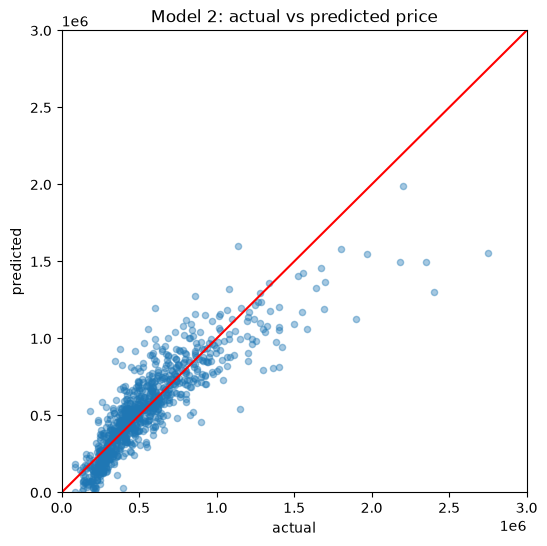

In [499]:
results = pd.DataFrame({"actual": y_test, "predicted": y_pred2})

ax = results.plot.scatter(x="actual", y="predicted", alpha=0.4, figsize=(6, 6),
                          title="Model 2: actual vs predicted price")
ax.plot([0, 3_000_000], [0, 3_000_000], color="red")     # the line of perfect predictions
ax.set_xlim(0, 3_000_000)
ax.set_ylim(0, 3_000_000)

print("Test houses outside the 3,000,000 view:", (results["actual"] > 3_000_000).sum())

### 12.7 Model Comparison
The baseline, the first model and the new model are compared on the same test houses.

In [500]:
comparison = pd.DataFrame({
    "Model": ["Baseline (average price)", "Model 1: city columns", "Model 2: zip code rate"],
    "Columns": [0, 29, 11],
    "Test MAE": [baseline_mae, mae, mae2],
})
comparison["Test MAE"] = comparison["Test MAE"].round(0).astype(int)
comparison["Better than baseline (%)"] = ((baseline_mae - comparison["Test MAE"]) / baseline_mae * 100).round(1) + 0
comparison

,Model,Columns,Test MAE,Better than baseline (%)
0,Baseline (average price),0,235839,0.0
1,Model 1: city columns,29,126934,46.2
2,Model 2: zip code rate,11,110294,53.2


<Axes: title={'center': 'Test MAE by model (lower is better)'}, ylabel='Model'>

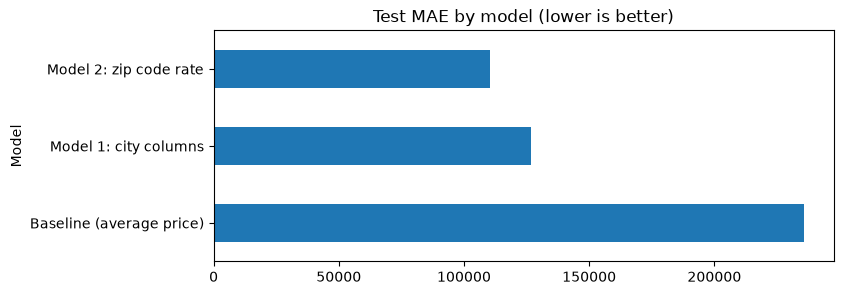

In [501]:
comparison.set_index("Model")["Test MAE"].plot.barh(title="Test MAE by model (lower is better)", figsize=(8, 3))

### 12.8 Conclusion

| Model | Columns | Test MAE |
|---|---|---|
| Baseline (average price) | 0 | 235,839 |
| Model 1: city columns | 29 | 126,934 |
| Model 2: zip code rate | 11 | 110,294 |

Replacing the 19 city columns with a single zip code rate column reduces the test MAE by about 13% (from 126,934 to 110,294) while using 18 fewer columns. The zip code separates neighbourhoods inside large cities such as Seattle, which the city columns could not do. The rate is calculated from the training houses only, so the test houses were not used in building it.

**Decision:** Model 2 is used as the final model.

**Limitation:** The typical error is still about 110,000. The model does not use finish quality, street or exact location.

## 13. Interactive Prediction

The model requires 11 feature values. The user is asked for each of the 10 house features and for the zip code, which is converted to the zip rate. If the user does not know a value, pressing Enter uses the median value of the training houses.

### 13.1 Typical Values
The median of each feature is calculated from the training data.

In [502]:
typical_house = np.median(X2_train, axis=0)

pd.Series(typical_house, index=feature_cols_2)

sqft_living    1960.000000
bathrooms         2.250000
bedrooms          3.000000
floors            1.500000
waterfront        0.000000
view              0.000000
condition         3.000000
sqft_lot       7620.000000
yr_built       1976.000000
renovated         0.000000
zip_rate        248.519764
dtype: float64

### 13.2 Asking for a Value
The function asks one question. If the user presses Enter, the default value is returned. If the user types something that is not a number, the question is asked again.

In [503]:
def ask_number(question, default):
    while True:
        text = input(f"{question} [Enter = {default:g}]: ").strip()

        if text == "":
            print(f"   Using typical value: {default:g}")
            return default

        try:
            return float(text)
        except ValueError:
            print("   Please enter a number, or press Enter to skip.")

### 13.3 Asking for the Zip Code
The user enters a zip code, such as 98034. It is looked up in the zip rate table calculated from the training houses. If the zip code is not in the table, the question is asked again. Pressing Enter uses the median rate.

In [504]:
def ask_zip_rate(default):
    while True:
        text = input("Zip code, for example 98034 [Enter = typical area]: ").strip()

        if text == "":
            print(f"   Using typical rate: ${default:.0f} per sq ft")
            return default

        key = "WA " + text
        if key in zip_rate.index:
            return zip_rate[key]

        print("   Zip code not found in the data. Try again, or press Enter to skip.")

### 13.4 Prediction Program
The program asks for the 10 house features and the zip code. Skipped values are replaced by the typical value. The values are arranged in the order the model expects, and the predicted price is calculated as in the evaluation: `b2 + np.dot(house, w2)`.

A warning is shown if the living area is outside the range of the training data, because the model has not seen such houses.

In [505]:
questions = [
    "Living area in square feet",
    "Number of bathrooms",
    "Number of bedrooms",
    "Number of floors",
    "Waterfront? (1 = yes, 0 = no)",
    "View rating (0 to 4)",
    "Condition rating (1 to 5)",
    "Lot size in square feet",
    "Year built",
    "Renovated? (1 = yes, 0 = no)",
]

In [506]:
def predict_house_price():
    values = []

    for i, question in enumerate(questions):
        values.append(ask_number(question, typical_house[i]))

    values.append(ask_zip_rate(typical_house[10]))

    if values[0] <= 0:
        print("Living area must be greater than zero.")
        return

    low, high = X2_train[:, 0].min(), X2_train[:, 0].max()
    if not (low <= values[0] <= high):
        print(f"Warning: the model saw living areas from {low:.0f} to {high:.0f} sq ft, "
              "so this prediction is less reliable.")

    print("\nValues used:")
    print(pd.Series(values, index=feature_cols_2).round(2).to_string())

    house = np.array(values)
    predicted = b2 + np.dot(house, w2)
    print(f"\nPredicted house price: ${predicted:,.0f}")

In [507]:
predict_house_price()

   Using typical value: 1960
   Using typical value: 2.25
   Using typical value: 3
   Using typical value: 1.5
   Using typical value: 0
   Using typical value: 0
   Using typical value: 3
   Using typical value: 7620
   Using typical value: 1976
   Using typical value: 0
   Using typical rate: $249 per sq ft

Values used:
sqft_living    1960.00
bathrooms         2.25
bedrooms          3.00
floors            1.50
waterfront        0.00
view              0.00
condition         3.00
sqft_lot       7620.00
yr_built       1976.00
renovated         0.00
zip_rate        248.52

Predicted house price: $457,897


## 14. Challenges

| Challenge | Where |
|---|---|
| A: Find unusual houses | Section 14.1 |
| B: Shuffle the dataset | Sections 8 and 14.2 |
| C: Compare predictions with a baseline | Sections 11, 12.7 and 14.3 |
| D: Write a mini-report | Section 15 |

### 14.1 Challenge A: Unusual House
A house with an unusually high price (50,000,000) is added to the cleaned prices. The mean and median are compared before and after. `np.append` returns a new array, so `y` itself is not changed.

In [508]:
y_unusual = np.append(y, 50_000_000)

compare = pd.DataFrame({
    "before": [np.mean(y), np.median(y)],
    "after":  [np.mean(y_unusual), np.median(y_unusual)],
}, index=["mean", "median"])
compare["change"] = compare["after"] - compare["before"]

compare.round(0)

,before,after,change
mean,548336.0,559223.0,10888.0
median,465000.0,465000.0,0.0


#### Effect on the Regression Model

The same unusual house is now added to the training data of the final model (Model 2), and the model is fitted again. The house is a copy of a training house with its size set to 1,500 sq ft and its price set to $50,000,000. The test error is compared before and after.

In [509]:
unusual_house = X2_train[0].copy()
unusual_house[0] = 1500

X2_train_u = np.vstack([X2_train, unusual_house])
y_train_u = np.append(y_train, 50_000_000)

X2_train_u_b = np.column_stack([np.ones(len(X2_train_u)), X2_train_u])
weights_u = np.linalg.lstsq(X2_train_u_b, y_train_u, rcond=None)[0]

y_pred_u = weights_u[0] + np.dot(X2_test, weights_u[1:])
mae_u = np.mean(np.abs(y_test - y_pred_u))

print("Test MAE before adding the house: $", f"{mae2:,.0f}")
print("Test MAE after adding the house : $", f"{mae_u:,.0f}")

Test MAE before adding the house: $ 110,294
Test MAE after adding the house : $ 112,284


#### Observations on Challenge A

- **Mean vs median:** The mean uses every value, so one house with a price of 50,000,000 raised it by about 10,900. The median depends only on the middle position of the sorted prices, so the extreme value does not change it.
- **Effect on the model:** Least squares squares the prediction errors, so one very large error has a very large effect on the fitted weights. Adding a single unusual house made the test MAE about 2% worse (110,294 to 112,284).
- **Connection to cleaning:** This is why the extreme records, such as 26,590,000 for 1,180 sq ft, were removed in Section 4.3.

### 14.2 Challenge B: Shuffle the Dataset

Completed in **Section 8**. The row positions were shuffled with one shared permutation (`order = np.random.permutation(len(X))`) and applied to both `X` and `y`, so every house stays paired with its price. The pairing was checked in Section 8.1, and the shuffled data was then split 80/20 into training and test sets.

### 14.3 Challenge C: Compare Predictions with a Baseline

Completed in **Section 11** and **Section 12.7**. The baseline predicts the average training price for every test house. Its test MAE (235,839) is compared with the test MAE of Model 1 (126,934) and Model 2 (110,294), so the final model's error is about 53% lower than the baseline's.

## 15. Summary and Limitations

### Objective
Predict the sale price of a house from its features using multiple linear regression implemented with NumPy.

### Data
Kaggle house price data (Seattle area), 4,600 records. After removing 49 zero-price records, 2 records with zero bedrooms or bathrooms and 8 price outliers, 4,541 records remained. The target is `price` in US dollars.

### Method
- Features were selected by analysing the data: columns with no information (`country`, `street`), redundant columns (`sqft_above`, `sqft_basement`, which add up to `sqft_living`) and a column with a very short time span (`date`) were excluded.
- `yr_renovated` was converted to a binary `renovated` feature.
- The data was shuffled with one shared permutation and split 80% for training and 20% for testing.
- Weights were estimated by least squares (`np.linalg.lstsq`).
- Model 1 represented location with 19 binary city columns. Model 2 represents it with one column: the average price per square foot of the zip code, calculated from the training houses only.

### How the Model Works
The model predicts a price as a weighted sum of a house's features plus a starting value (the intercept). Each weight says how many dollars a feature adds to the predicted price, with the other features held constant.

The weights are learned from the training houses by least squares: NumPy finds the weights and intercept that make the total squared prediction error on those houses as small as possible. The fitted model is then tested on houses it never saw, to measure how well it predicts new data.

### Results
The three models are compared on the same 909 test houses. MSE is in squared dollars.

In [513]:
baseline_mse = np.mean(baseline_errors ** 2)

final_results = pd.DataFrame({
    "Model": ["Baseline (average training price)", "Model 1: city columns", "Model 2: zip code rate (final)"],
    "Columns": [0, 29, 11],
    "Test MAE ($)": [baseline_mae, mae, mae2],
    "Test MSE": [baseline_mse, mse, mse2],
})
final_results["MAE better than baseline (%)"] = (
    (baseline_mae - final_results["Test MAE ($)"]) / baseline_mae * 100
).round(1)

final_results.style.hide(axis="index").format({
    "Test MAE ($)": "{:,.0f}",
    "Test MSE": "{:,.0f}",
    "MAE better than baseline (%)": "{:.1f}",
})

Model,Columns,Test MAE ($),Test MSE,MAE better than baseline (%)
Baseline (average training price),0,"235,839","149,088,754,915",0.0
Model 1: city columns,29,"126,934","50,844,207,968",46.2
Model 2: zip code rate (final),11,"110,294","40,052,814,303",53.2


The final model (Model 2) has a test MAE of about $110,294, a test MSE of about 40.05 billion (squared dollars) and an RMSE of about $200,132. Its predictions are on average about $110,000 away from the actual price, which is 53% lower than the baseline's error.

#### Learned Parameters and Sample Predictions
The intercept and weights of the final model are printed below, followed by the first five test predictions. The weights show the main drivers of price: each extra square foot adds about $246, a waterfront location adds about $381,000, each step up the view rating adds about $50,000, and each extra dollar of zip-code price per square foot adds about $2,102.

In [514]:
print(f"Intercept b2: {b2:,.1f}\n")
print(pd.Series(w2, index=feature_cols_2).round(2).to_string())

print(f"\nTest MAE : ${mae2:,.0f}")
print(f"Test MSE : {mse2:,.0f}")
print(f"Test RMSE: ${rmse2:,.0f}")

sample = pd.DataFrame({
    "actual": y_test[:5],
    "predicted": y_pred2[:5].round(0),
})
sample["error (actual - predicted)"] = sample["actual"] - sample["predicted"]
sample

Intercept b2: -1,053,253.8

sqft_living       246.27
bathrooms       12424.58
bedrooms       -25283.94
floors         -14263.43
waterfront     380728.02
view            50160.98
condition       28294.97
sqft_lot           -0.10
yr_built          248.61
renovated       14033.43
zip_rate         2102.00

Test MAE : $110,294
Test MSE : 40,052,814,303
Test RMSE: $200,132


,actual,predicted,error (actual - predicted)
0,489200.0,514827.0,-25627.0
1,324950.0,254250.0,70700.0
2,420000.0,584150.0,-164150.0
3,900000.0,456075.0,443925.0
4,590000.0,375102.0,214898.0


### Limitations
- The typical error (about $110,000) is still large. The model does not use finish quality, the street or the exact location.
- The model is linear, so it assumes each feature adds a fixed amount to the price.
- The model has one set of weights for the whole region, so it cannot capture effects that differ between areas, such as size mattering more in expensive zip codes.
- The zip-code rate of a training house is calculated from prices that include that house's own price, so the fit on the training data is slightly optimistic. The test results are not affected, because the test houses were not used to calculate the rates.
- The data covers 10 weeks in 2014 in one region, so it does not describe current prices or other places.
- The price outlier thresholds (price per sq ft between 50 and 1,000) were chosen by inspecting the data and are a judgement.
- The interactive program fills skipped values with typical values, so its prediction is for an average house of that size and location.

### Reflection

**What worked**
- Cleaning the data first (zero prices and extreme price-per-square-foot values) removed records that would have distorted the fitted line.
- Replacing 19 city columns with one zip-code rate column lowered the test error (126,934 to 110,294) with 18 fewer columns, because zip code separates neighbourhoods inside large cities such as Seattle.
- Comparing against a baseline showed that the model learned real patterns and was not just fitting noise.

**What I learned**
- A model must be evaluated on held-out houses, because error on the training data looks better than real performance.
- Least squares finds all the weights at once, and a column of ones lets the intercept be learned like any other weight.
- A single extreme price can shift the mean and the fitted weights, while the median stays unchanged (Challenge A).
- Shuffling `X` and `y` with one shared permutation keeps each house paired with its price (Challenge B).
- A feature's weight depends on the other features in the model. For example, `bedrooms` has a negative weight when `sqft_living` is held constant.